# Notebook 04: Temporal Window Ablation & Personalization Scope (Revision 12)
Evaluates diagnostic contributions across early ($0–500\text{ ms}$), intermediate ($500–1000\text{ ms}$), late ($1000–2000\text{ ms}$), and full exploration ($0–7500\text{ ms}$) windows.

### Research Scope Note on Personalized Calibration:
Personalized baseline z-score normalization (`Mode B`) is marked as **proposed and pending validation**. On the Zenodo dataset, participants have limited neutral calibration exposures ($N_{\text{calib}} \le 7$), causing small-sample variance to inflate test estimation error compared to regularized population-level models.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

base_dir = r"E:\karthianna"
ablation_path = os.path.join(base_dir, "outputs", "temporal_ablation_results.csv")
df_temp = pd.read_csv(ablation_path)

print("Temporal Latency Window Breakdown (Random Forest, StratifiedGroupKFold):")
print(df_temp[['window_name', 'temporal_range_ms', 'n_features', 'participant_balanced_accuracy_pct', 'participant_roc_auc', 'trial_balanced_accuracy']])

Temporal Latency Window Breakdown (Random Forest, StratifiedGroupKFold):
                                 window_name  ... trial_balanced_accuracy
0                    Early Window (0-500 ms)  ...                  0.5187
1                   Mid Window (500-1000 ms)  ...                  0.5119
2                 Late Window (1000-2000 ms)  ...                  0.5244
3         Full Trial Exploration (0-7500 ms)  ...                  0.5994
4  Multi-Temporal Baseline (All 11 Features)  ...                  0.5994
[5 rows x 6 columns]


<string>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


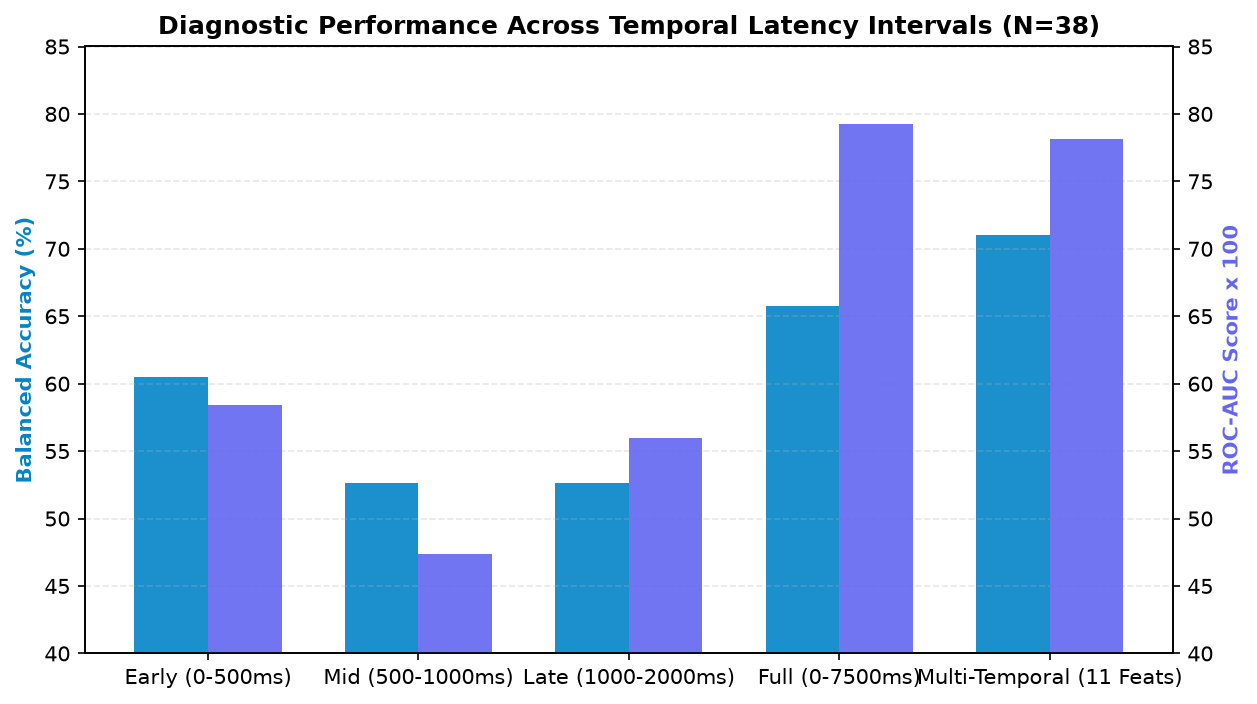

In [2]:
windows = [
    'Early (0-500ms)',
    'Mid (500-1000ms)',
    'Late (1000-2000ms)',
    'Full (0-7500ms)',
    'Multi-Temporal (11 Feats)'
]
bacc = df_temp['participant_balanced_accuracy_pct'].values
auc = df_temp['participant_roc_auc'].values

fig, ax1 = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(windows))
w = 0.35

ax1.bar(x - w/2, bacc, w, label='Participant Bal Acc (%)', color='#0284C7', alpha=0.9)
ax1.set_ylabel('Balanced Accuracy (%)', color='#0284C7', fontweight='bold')
ax1.set_ylim([40, 85])

ax2 = ax1.twinx()
ax2.bar(x + w/2, auc * 100, w, label='Participant ROC-AUC (x100)', color='#6366F1', alpha=0.9)
ax2.set_ylabel('ROC-AUC Score x 100', color='#6366F1', fontweight='bold')
ax2.set_ylim([40, 85])

ax1.set_xticks(x)
ax1.set_xticklabels(windows, fontsize=10)
ax1.set_title('Diagnostic Performance Across Temporal Latency Intervals (N=38)', fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.3, axis='y')
plt.tight_layout()
plt.show()